In [2]:
import os
import shutil
import zipfile
from pathlib import Path
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Extract dataset
ZIP_PATH = '/content/drive/MyDrive/fish_dataset.zip'  # Update if placed in a subfolder in Drive
EXTRACT_PATH = Path('/content/dataset_raw')
WORK_DIR = Path('/content/fish_project')
MODEL_DIR = WORK_DIR / 'models'
PLOT_DIR = WORK_DIR / 'plots'

MODEL_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

if not EXTRACT_PATH.exists():
    print("Extracting dataset...")
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_PATH)
    print("Extraction completed.")

# 3. Automatically detect the folder containing the actual class folders
# (Ignores Kaggle mask/ground-truth folders such as 'GT')
candidate_dirs = []
for root, dirs, files in os.walk(EXTRACT_PATH):
    valid_subdirs = [
        d for d in dirs
        if not d.lower().endswith('gt') and 'mask' not in d.lower() and not d.startswith('.')
    ]
    if len(valid_subdirs) >= 2:
        candidate_dirs.append((root, valid_subdirs))

if not candidate_dirs:
    raise ValueError("Could not automatically locate class subfolders. Verify your zip contents.")

# Select the deepest folder with valid class subdirectories
candidate_dirs.sort(key=lambda x: len(Path(x[0]).parts), reverse=True)
DATA_DIR = Path(candidate_dirs[0][0])
print(f"Dataset root identified at: {DATA_DIR}")
print(f"Detected subfolders ({len(candidate_dirs[0][1])}): {candidate_dirs[0][1]}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset root identified at: /content/dataset_raw/fish_dataset/data/val
Detected subfolders (11): ['fish sea_food striped_red_mullet', 'fish sea_food gilt_head_bream', 'fish sea_food sea_bass', 'animal fish', 'fish sea_food black_sea_sprat', 'fish sea_food shrimp', 'fish sea_food trout', 'fish sea_food red_sea_bream', 'fish sea_food hourse_mackerel', 'fish sea_food red_mullet', 'animal fish bass']


In [3]:
import os
import json
import numpy as np
from pathlib import Path
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Project directories
WORK_DIR = Path('/content/fish_project')
MODEL_DIR = WORK_DIR / 'models'
PLOT_DIR = WORK_DIR / 'plots'

MODEL_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# Configuration matching your verified output
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 12
RANDOM_SEED = 42

# DATA_DIR should point to the folder containing the 11 species folders
# (e.g., DATA_DIR = Path('/content/fish_data_raw/...'))
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    rotation_range=30,
    zoom_range=0.2,
    horizontal_flip=True,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    fill_mode='nearest',
    validation_split=0.3
)

val_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    validation_split=0.3
)

train_gen = train_datagen.flow_from_directory(
    DATA_DIR,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    seed=RANDOM_SEED,
    shuffle=True
)

val_gen = val_datagen.flow_from_directory(
    DATA_DIR,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    seed=RANDOM_SEED,
    shuffle=False
)

NUM_CLASSES = train_gen.num_classes
CLASS_NAMES = list(train_gen.class_indices.keys())

# Save class labels for Streamlit deployment
with open(WORK_DIR / 'class_names.json', 'w') as f:
    json.dump(CLASS_NAMES, f)

print(f"Verified {NUM_CLASSES} classes: {CLASS_NAMES}")

Found 767 images belonging to 11 classes.
Found 325 images belonging to 11 classes.
Verified 11 classes: ['animal fish', 'animal fish bass', 'fish sea_food black_sea_sprat', 'fish sea_food gilt_head_bream', 'fish sea_food hourse_mackerel', 'fish sea_food red_mullet', 'fish sea_food red_sea_bream', 'fish sea_food sea_bass', 'fish sea_food shrimp', 'fish sea_food striped_red_mullet', 'fish sea_food trout']


In [4]:
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.applications import (
    VGG16,
    ResNet50,
    MobileNet,
    InceptionV3,
    EfficientNetB0
)

def build_custom_cnn(input_shape=(224, 224, 3), num_classes=NUM_CLASSES):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(256, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ], name='CustomCNN')

    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

def build_transfer_model(base_model_fn, model_name, input_shape=(224, 224, 3), num_classes=NUM_CLASSES):
    base_model = base_model_fn(weights='imagenet', include_top=False, input_shape=input_shape)
    base_model.trainable = False

    inputs = layers.Input(shape=input_shape)
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = models.Model(inputs, outputs, name=model_name)
    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

In [5]:
import gc
import pickle

def get_callbacks(model_name):
    # Only checkpoints and LR scheduling (No EarlyStopping included)
    return [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(MODEL_DIR / f"{model_name}_best.h5"),
            monitor="val_accuracy",
            save_best_only=True,
            save_weights_only=False,
            verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=3,
            min_lr=1e-6,
            verbose=1
        )
    ]

model_factories = {
    'CustomCNN': lambda: build_custom_cnn(),
    'VGG16': lambda: build_transfer_model(VGG16, 'VGG16'),
    'ResNet50': lambda: build_transfer_model(ResNet50, 'ResNet50'),
    'MobileNet': lambda: build_transfer_model(MobileNet, 'MobileNet'),
    'InceptionV3': lambda: build_transfer_model(InceptionV3, 'InceptionV3'),
    'EfficientNetB0': lambda: build_transfer_model(EfficientNetB0, 'EfficientNetB0')
}

histories = {}
BASE_EPOCHS = 15
FINE_TUNE_EPOCHS = 5

for name, factory in model_factories.items():
    print(f"\n{'='*45}\nTraining Model: {name}\n{'='*45}")
    model = factory()

    # 1. Base training run (completes all epochs without early exit)
    history = model.fit(
        train_gen,
        validation_data=val_gen,
        epochs=BASE_EPOCHS,
        callbacks=get_callbacks(name)
    )

    # 2. Fine-tuning top layers for transfer architectures
    if name != 'CustomCNN':
        print(f"\n--- Fine-tuning {name} ---")
        base_layer = model.layers[1]
        base_layer.trainable = True

        # Unfreeze the top 20 layers
        for layer in base_layer.layers[:-20]:
            layer.trainable = False

        model.compile(
            optimizer=optimizers.Adam(learning_rate=1e-5),
            loss='categorical_crossentropy',
            metrics=['accuracy']
        )

        ft_history = model.fit(
            train_gen,
            validation_data=val_gen,
            epochs=FINE_TUNE_EPOCHS,
            callbacks=get_callbacks(name)
        )

        # Merge metrics histories
        for metric in history.history:
            history.history[metric].extend(ft_history.history[metric])

    histories[name] = history.history
    with open(MODEL_DIR / f"{name}_history.pkl", 'wb') as f:
        pickle.dump(history.history, f)

    del model
    gc.collect()
    tf.keras.backend.clear_session()


Training Model: CustomCNN
Epoch 1/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 361ms/step - accuracy: 0.2518 - loss: 2.9643
Epoch 1: val_accuracy improved from None to 0.20308, saving model to /content/fish_project/models/CustomCNN_best.h5



Epoch 1: finished saving model to /content/fish_project/models/CustomCNN_best.h5
64/64 ━━━━━━━━━━━━━━━━━━━━ 45s 452ms/step - accuracy: 0.3038 - loss: 2.6325 - val_accuracy: 0.2031 - val_loss: 5.3722 - learning_rate: 0.0010
Epoch 2/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step - accuracy: 0.4093 - loss: 1.9709
Epoch 2: val_accuracy did not improve from 0.20308
64/64 ━━━━━━━━━━━━━━━━━━━━ 14s 215ms/step - accuracy: 0.4211 - loss: 1.8819 - val_accuracy: 0.1754 - val_loss: 9.3637 - learning_rate: 0.0010
Epoch 3/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step - accuracy: 0.4432 - loss: 1.7729
Epoch 3: val_accuracy did not improve from 0.20308
64/64 ━━━━━━━━━━━━━━━━━━━━ 12s 190ms/step - accuracy: 0.4459 - loss: 1.7372 - val_accuracy: 0.1692 - val_loss: 7.5032 - learning_rate: 0.0010
Epoch 4/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step - accuracy: 0.4736 - loss: 1.6272
Epoch 4: val_accuracy improved from 0.20308 to 0.23077, saving model to /content/fish_project/models/CustomCNN_best.h5



Epoch 4: finished saving model to /content/fish_project/models/CustomCNN_best.h5

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.00020000000949949026.
64/64 ━━━━━━━━━━━━━━━━━━━━ 22s 220ms/step - accuracy: 0.5020 - loss: 1.5817 - val_accuracy: 0.2308 - val_loss: 8.1347 - learning_rate: 0.0010
Epoch 5/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/step - accuracy: 0.5878 - loss: 1.2248
Epoch 5: val_accuracy did not improve from 0.23077
64/64 ━━━━━━━━━━━━━━━━━━━━ 13s 208ms/step - accuracy: 0.5789 - loss: 1.3058 - val_accuracy: 0.2246 - val_loss: 6.0854 - learning_rate: 2.0000e-04
Epoch 6/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.5936 - loss: 1.2720
Epoch 6: val_accuracy improved from 0.23077 to 0.33231, saving model to /content/fish_project/models/CustomCNN_best.h5



Epoch 6: finished saving model to /content/fish_project/models/CustomCNN_best.h5
64/64 ━━━━━━━━━━━━━━━━━━━━ 14s 224ms/step - accuracy: 0.5997 - loss: 1.2169 - val_accuracy: 0.3323 - val_loss: 2.7983 - learning_rate: 2.0000e-04
Epoch 7/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step - accuracy: 0.5990 - loss: 1.1474
Epoch 7: val_accuracy improved from 0.33231 to 0.36923, saving model to /content/fish_project/models/CustomCNN_best.h5



Epoch 7: finished saving model to /content/fish_project/models/CustomCNN_best.h5
64/64 ━━━━━━━━━━━━━━━━━━━━ 13s 209ms/step - accuracy: 0.6037 - loss: 1.1536 - val_accuracy: 0.3692 - val_loss: 2.4022 - learning_rate: 2.0000e-04
Epoch 8/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step - accuracy: 0.6421 - loss: 1.0219
Epoch 8: val_accuracy improved from 0.36923 to 0.47692, saving model to /content/fish_project/models/CustomCNN_best.h5


...


Epoch 10: finished saving model to /content/fish_project/models/InceptionV3_best.h5
64/64 ━━━━━━━━━━━━━━━━━━━━ 15s 230ms/step - accuracy: 0.9557 - loss: 0.1347 - val_accuracy: 0.9538 - val_loss: 0.1566 - learning_rate: 2.0000e-04
Epoch 11/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step - accuracy: 0.9453 - loss: 0.1775
Epoch 11: val_accuracy did not improve from 0.95385
64/64 ━━━━━━━━━━━━━━━━━━━━ 14s 215ms/step - accuracy: 0.9361 - loss: 0.1829 - val_accuracy: 0.9477 - val_loss: 0.1577 - learning_rate: 2.0000e-04
Epoch 12/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step - accuracy: 0.9529 - loss: 0.1752
Epoch 12: val_accuracy did not improve from 0.95385
64/64 ━━━━━━━━━━━━━━━━━━━━ 14s 213ms/step - accuracy: 0.9452 - loss: 0.1807 - val_accuracy: 0.9415 - val_loss: 0.1592 - learning_rate: 2.0000e-04
Epoch 13/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step - accuracy: 0.9593 - loss: 0.1356
Epoch 13: val_accuracy did not improve from 0.95385
64/64 ━━━━━━━━━━━━━━━━━━━━ 14s 213ms/step - accuracy: 0.9570


Epoch 1: finished saving model to /content/fish_project/models/InceptionV3_best.h5
64/64 ━━━━━━━━━━━━━━━━━━━━ 59s 588ms/step - accuracy: 0.9544 - loss: 0.1535 - val_accuracy: 0.9538 - val_loss: 0.1443 - learning_rate: 1.0000e-05
Epoch 2/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step - accuracy: 0.9154 - loss: 0.2069
Epoch 2: val_accuracy did not improve from 0.95385
64/64 ━━━━━━━━━━━━━━━━━━━━ 14s 219ms/step - accuracy: 0.9309 - loss: 0.1845 - val_accuracy: 0.9508 - val_loss: 0.1387 - learning_rate: 1.0000e-05
Epoch 3/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step - accuracy: 0.9561 - loss: 0.1381
Epoch 3: val_accuracy did not improve from 0.95385
64/64 ━━━━━━━━━━━━━━━━━━━━ 14s 216ms/step - accuracy: 0.9518 - loss: 0.1500 - val_accuracy: 0.9477 - val_loss: 0.1355 - learning_rate: 1.0000e-05
Epoch 4/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step - accuracy: 0.9616 - loss: 0.1348
Epoch 4: val_accuracy did not improve from 0.95385
64/64 ━━━━━━━━━━━━━━━━━━━━ 14s 215ms/step - accuracy: 0.9505 - loss: 0


Epoch 1: finished saving model to /content/fish_project/models/EfficientNetB0_best.h5
64/64 ━━━━━━━━━━━━━━━━━━━━ 74s 691ms/step - accuracy: 0.1069 - loss: 2.6617 - val_accuracy: 0.1723 - val_loss: 2.3758 - learning_rate: 0.0010
Epoch 2/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step - accuracy: 0.1315 - loss: 2.5225
Epoch 2: val_accuracy did not improve from 0.17231
64/64 ━━━━━━━━━━━━━━━━━━━━ 11s 175ms/step - accuracy: 0.1134 - loss: 2.5232 - val_accuracy: 0.0923 - val_loss: 2.5472 - learning_rate: 0.0010
Epoch 3/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step - accuracy: 0.1316 - loss: 2.5090
Epoch 3: val_accuracy did not improve from 0.17231
64/64 ━━━━━━━━━━━━━━━━━━━━ 13s 202ms/step - accuracy: 0.1330 - loss: 2.5060 - val_accuracy: 0.0892 - val_loss: 2.4582 - learning_rate: 0.0010
Epoch 4/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step - accuracy: 0.1534 - loss: 2.4485
Epoch 4: val_accuracy did not improve from 0.17231

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.00020000000949949026


Epoch 14: finished saving model to /content/fish_project/models/EfficientNetB0_best.h5
64/64 ━━━━━━━━━━━━━━━━━━━━ 13s 201ms/step - accuracy: 0.1317 - loss: 2.4289 - val_accuracy: 0.1908 - val_loss: 2.3095 - learning_rate: 4.0000e-05
Epoch 15/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - accuracy: 0.1522 - loss: 2.3503
Epoch 15: val_accuracy did not improve from 0.19077
64/64 ━━━━━━━━━━━━━━━━━━━━ 12s 193ms/step - accuracy: 0.1421 - loss: 2.3794 - val_accuracy: 0.1200 - val_loss: 2.3378 - learning_rate: 4.0000e-05

--- Fine-tuning EfficientNetB0 ---
Epoch 1/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 445ms/step - accuracy: 0.1107 - loss: 3.1972
Epoch 1: val_accuracy improved from None to 0.17231, saving model to /content/fish_project/models/EfficientNetB0_best.h5



Epoch 1: finished saving model to /content/fish_project/models/EfficientNetB0_best.h5
64/64 ━━━━━━━━━━━━━━━━━━━━ 73s 673ms/step - accuracy: 0.1069 - loss: 3.1562 - val_accuracy: 0.1723 - val_loss: 2.4889 - learning_rate: 1.0000e-05
Epoch 2/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step - accuracy: 0.1126 - loss: 2.9766
Epoch 2: val_accuracy did not improve from 0.17231
64/64 ━━━━━━━━━━━━━━━━━━━━ 13s 204ms/step - accuracy: 0.1239 - loss: 2.9454 - val_accuracy: 0.1723 - val_loss: 2.6156 - learning_rate: 1.0000e-05
Epoch 3/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step - accuracy: 0.1091 - loss: 2.9996
Epoch 3: val_accuracy did not improve from 0.17231
64/64 ━━━━━━━━━━━━━━━━━━━━ 13s 201ms/step - accuracy: 0.1199 - loss: 2.9270 - val_accuracy: 0.1723 - val_loss: 2.6986 - learning_rate: 1.0000e-05
Epoch 4/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step - accuracy: 0.1211 - loss: 2.9515
Epoch 4: val_accuracy did not improve from 0.17231

Epoch 4: ReduceLROnPlateau reducing learning rate to 1.99999994947


FINAL MODEL COMPARISON METRICS
         Model  Accuracy  Precision (Macro)  Recall (Macro)  F1-Score (Macro)
     MobileNet    0.9754             0.9788          0.9223            0.9345
         VGG16    0.9538             0.8716          0.8734            0.8709
   InceptionV3    0.9538             0.9623          0.9011            0.9160
     CustomCNN    0.7692             0.7007          0.6892            0.6867
      ResNet50    0.1077             0.0299          0.1097            0.0361
EfficientNetB0    0.0923             0.0084          0.0909            0.0154

Top Model: MobileNet with Accuracy: 97.54%
Saved to: /content/fish_project/best_fish_model.h5


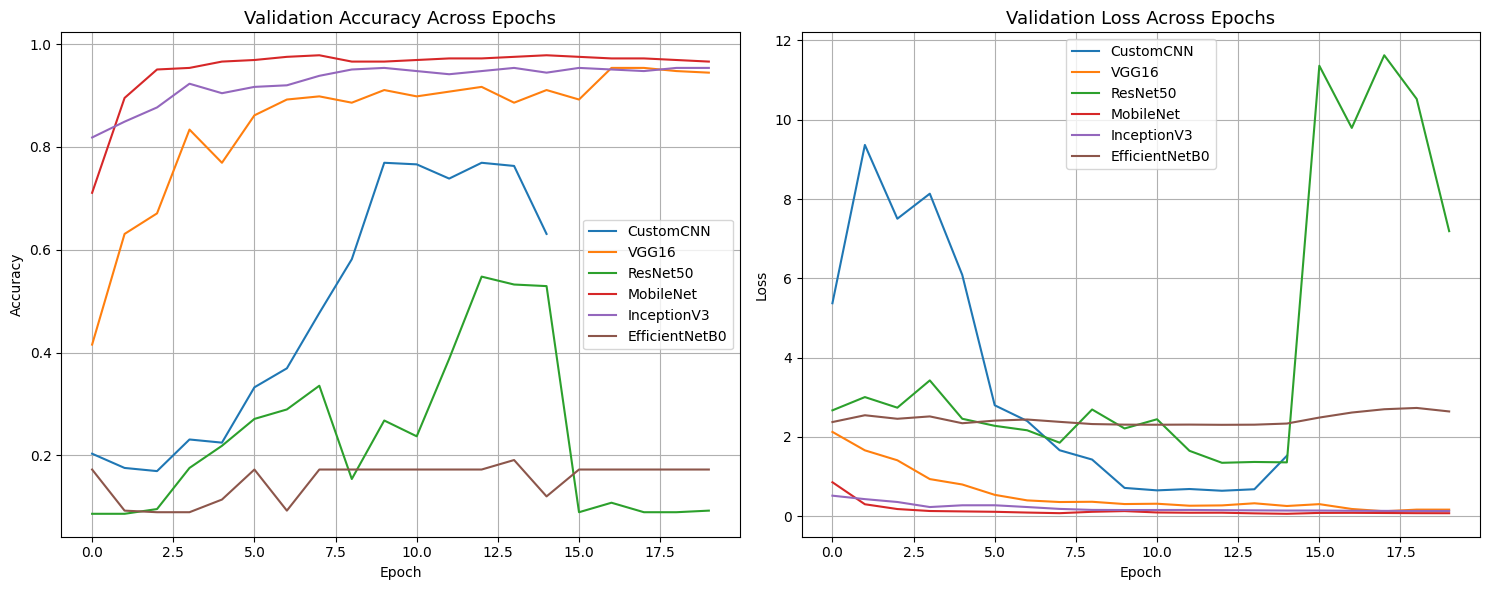

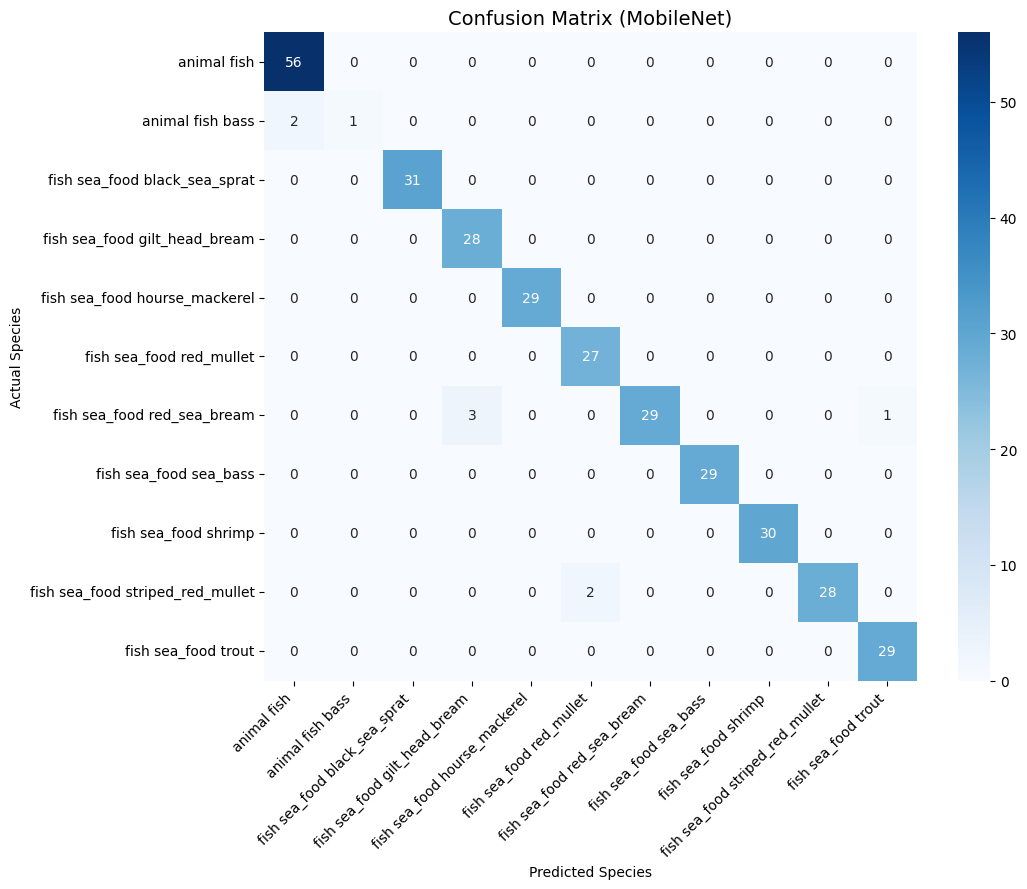

In [6]:
import shutil
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

evaluation_records = []
y_true = val_gen.classes
best_overall_acc = -1.0
best_model_name = ""

for name in model_factories.keys():
    model_path = MODEL_DIR / f"{name}_best.h5"
    if not model_path.exists():
        continue

    model = tf.keras.models.load_model(model_path)
    val_gen.reset()
    y_pred_probs = model.predict(val_gen, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)

    acc = accuracy_score(y_true, y_pred)
    report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, output_dict=True, zero_division=0)

    evaluation_records.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision (Macro)': round(report['macro avg']['precision'], 4),
        'Recall (Macro)': round(report['macro avg']['recall'], 4),
        'F1-Score (Macro)': round(report['macro avg']['f1-score'], 4)
    })

    if acc > best_overall_acc:
        best_overall_acc = acc
        best_model_name = name
        shutil.copyfile(model_path, WORK_DIR / 'best_fish_model.h5')

    del model
    gc.collect()
    tf.keras.backend.clear_session()

# 1. Output comparison table
comparison_df = pd.DataFrame(evaluation_records).sort_values(by='Accuracy', ascending=False)
comparison_df.to_csv(WORK_DIR / 'model_comparison_report.csv', index=False)

print("\n" + "="*50)
print("FINAL MODEL COMPARISON METRICS")
print("="*50)
print(comparison_df.to_string(index=False))
print(f"\nTop Model: {best_model_name} with Accuracy: {best_overall_acc * 100:.2f}%")
print(f"Saved to: {WORK_DIR / 'best_fish_model.h5'}")

# 2. Plot Training & Validation Curves
plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
for name, hist in histories.items():
    plt.plot(hist['val_accuracy'], label=name)
plt.title("Validation Accuracy Across Epochs", fontsize=13)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
for name, hist in histories.items():
    plt.plot(hist['val_loss'], label=name)
plt.title("Validation Loss Across Epochs", fontsize=13)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig(PLOT_DIR / 'training_comparison_curves.png')
plt.show()

# 3. Best Model Confusion Matrix
best_model = tf.keras.models.load_model(WORK_DIR / 'best_fish_model.h5')
val_gen.reset()
y_pred_best = np.argmax(best_model.predict(val_gen, verbose=0), axis=1)
cm = confusion_matrix(y_true, y_pred_best)

plt.figure(figsize=(11, 9))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title(f"Confusion Matrix ({best_model_name})", fontsize=14)
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(PLOT_DIR / 'best_model_confusion_matrix.png')
plt.show()

In [7]:
%%writefile app.py
import json
import numpy as np
import streamlit as st
import tensorflow as tf
from PIL import Image

st.set_page_config(
    page_title="Fish Species Classifier",
    page_icon="🐟",
    layout="centered"
)

st.title("🐟 Multiclass Fish Species Classification")
st.write("Upload an image of a fish to identify its species and inspect model confidence.")

@st.cache_resource
def load_assets():
    model = tf.keras.models.load_model('fish_project/best_fish_model.h5')
    with open('fish_project/class_names.json', 'r') as f:
        labels = json.load(f)
    return model, labels

try:
    model, class_names = load_assets()
except Exception as err:
    st.error(f"Error loading model assets: {err}. Complete model training first.")
    st.stop()

uploaded_file = st.file_uploader("Select a fish image...", type=["jpg", "jpeg", "png"])

if uploaded_file is not None:
    image = Image.open(uploaded_file).convert("RGB")
    st.image(image, caption="Uploaded Image", use_container_width=True)

    # Preprocess image
    target_size = (224, 224)
    resized_image = image.resize(target_size)
    image_array = np.array(resized_image, dtype=np.float32) / 255.0
    input_tensor = np.expand_dims(image_array, axis=0)

    if st.button("Predict Species"):
        with st.spinner("Analyzing image..."):
            predictions = model.predict(input_tensor, verbose=0)[0]
            top_index = int(np.argmax(predictions))
            predicted_species = class_names[top_index].replace('_', ' ').title()
            confidence = float(predictions[top_index]) * 100.0

            st.success(f"**Predicted Category:** {predicted_species}")
            st.metric(label="Model Confidence", value=f"{confidence:.2f}%")

            st.write("### Top Predictions Breakdown")
            sorted_indices = np.argsort(predictions)[::-1][:5]
            for idx in sorted_indices:
                species = class_names[idx].replace('_', ' ').title()
                prob = float(predictions[idx])
                st.write(f"**{species}**: {prob * 100:.2f}%")
                st.progress(prob)

Writing app.py


In [ ]:
# 1. Install dependencies
!pip install -q streamlit
!wget -q -nc https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb
!dpkg -i cloudflared-linux-amd64.deb

# 2. Terminate any previous processes on port 8501
!fuser -k 8501/tcp

# 3. Start Streamlit in the background
get_ipython().system_raw('streamlit run app.py --server.port 8501 --server.enableCORS false --server.enableXsrfProtection false &')

# 4. Expose through Cloudflare
!cloudflared tunnel --url http://localhost:8501 --logfile /content/tunnel.log &

# 5. Retrieve public URL
import time, re
time.sleep(4)
with open('/content/tunnel.log') as f:
    log_content = f.read()
urls = re.findall(r'https://[a-zA-Z0-9-]+\.trycloudflare\.com', log_content)

if urls:
    print(f"\nDeployment URL: {urls[-1]}\n")
else:
    print("Check /content/tunnel.log for connection details.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 44.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 123.9 MB/s eta 0:00:00
Selecting previously unselected package cloudflared.
(Reading database ... 127332 files and directories currently installed.)
Preparing to unpack cloudflared-linux-amd64.deb ...
Unpacking cloudflared (2026.10.0) ...
Setting up cloudflared (2026.10.0) ...
Processing triggers for man-db (2.12.0-4build2) ...
2026-10-11T16:38:30Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https: